In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

HEATMAP_DIR = 'Results/heatmaps'
os.makedirs(HEATMAP_DIR, exist_ok=True)

In [2]:
# ── Experiment list ──────────────────────────────────────────────────────────
# Add or remove entries freely.  The loader handles two formats automatically:
#
#   Coarse scans  BPDwf shape (steps, 4, samples)  — axis-1 = oscilloscope channel
#                 Set ch= to the BPD channel index (2 for July 31 data).
#
#   Fine scans    BPDwf shape (steps, 10, samples) — axis-1 = repeated shots
#                 All 10 shots are averaged first, then baseline-stripped.
#                 ch is ignored for fine scans.

coarse_scans = [
    {'label': '0.5 nC (coarse)', 'path': 'Data_raw/July31_/CoarseScan0p5nC_5_1.npz',  'ch': 2},
    {'label': '1 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan1nC_6_6.npz',    'ch': 2},
    {'label': '4 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan4nC_4_5.npz',    'ch': 2},
    {'label': '7 nC (coarse)',   'path': 'Data_raw/July31_/CoarseScan7nC_4_2.npz',    'ch': 2},
    {'label': '10 nC (coarse)', 'path': 'Data_raw/July31_/CoarseScan10nC_4_0.npz',   'ch': 2},
]

fine_scans = [
    {'label': '0.25 nC (fine)', 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC (fine)',  'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC (fine)',   'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]

# Toggle which groups to include in the comparison plots
show_coarse = False
show_fine   = True

In [3]:

# ── Loader and baseline stripper ─────────────────────────────────────────────

from scipy.ndimage import uniform_filter1d

RF_Hz      = 81.25e6
mV         = 1e3
T_LASER_NS = 1e9 / RF_Hz   # ≈ 12.31 ns — one laser period

# ── Signal window definition ─────────────────────────────────────────────────
SIGNAL_START_NS = 45.
SIGNAL_END_NS   = 75.
FLANK_END_NS    = 100.

# ── Processing parameters ─────────────────────────────────────────────────────
BASELINE_MODE  = 'period_fill'
N_SVD          = 1
PROBE_HALF_WIN = 25

# FFT super-Gaussian low-pass filter.
#   FFT_SIGMA_GHZ : roll-off centre.  0 = disabled.
#   FFT_ORDER     : controls sharpness.  1 = standard Gaussian (gradual).
#                   Higher N → flatter passband, steeper cut.
#
#   Current settings (σ=0.35, N=6):
#     0.10 GHz → <0.01% attenuation   (signal fully preserved)
#     0.20 GHz → <0.07% attenuation   (signal fully preserved)
#     0.35 GHz → 39%   attenuation    (-3 dB point)
#     0.50 GHz → ~100% attenuation    (noise removed)
FFT_SIGMA_GHZ = 0.35
FFT_ORDER     = 3


def _period_fill_lookup(t_ns, signal_start, signal_end, flank_end):
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T_samp   = T_LASER_NS / dt_ns
    i_sig0   = int(round(signal_start / dt_ns))
    i_sig1   = int(round(signal_end   / dt_ns))
    i_fl_end = int(round(flank_end    / dt_ns))
    idx   = np.arange(i_sig0, i_sig1)
    n_l   = np.ceil((idx + 1 - i_sig0) / T_samp).astype(int)
    n_r   = np.ceil((i_sig1 - idx)     / T_samp).astype(int)
    src_l = np.round(idx - n_l * T_samp).astype(int)
    src_r = np.round(idx + n_r * T_samp).astype(int)
    return i_sig0, i_sig1, src_l, src_r


def fft_lowpass(residual, dt_ns, sigma_GHz, order=FFT_ORDER):
    """
    Super-Gaussian low-pass filter applied row-wise in the frequency domain.
      filter(f) = exp( -0.5 * (f/σ)^(2·order) )
    order=1 → standard Gaussian;  order>1 → flatter passband, sharper cut-off.
    """
    n     = residual.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)               # GHz
    filt  = np.exp(-0.5 * (freqs / sigma_GHz) ** (2 * order))
    F     = np.fft.rfft(residual, axis=1)
    return np.fft.irfft(F * filt[np.newaxis, :], n=n, axis=1)


def compute_baseline(traces, t_ns, mode, n_svd=N_SVD):
    if mode == 'period_fill':
        i_sig0, i_sig1, src_l, src_r = _period_fill_lookup(
            t_ns, SIGNAL_START_NS, SIGNAL_END_NS, FLANK_END_NS)
        baseline = traces.copy()
        baseline[:, i_sig0:i_sig1] = 0.5 * (traces[:, src_l] + traces[:, src_r])
        return baseline
    elif mode == 'mean_steps':
        mean_bl = traces.mean(axis=0)
        return np.tile(mean_bl, (traces.shape[0], 1))
    elif mode == 'scaled_mean':
        mean_bl = traces.mean(axis=0)
        scales  = (traces @ mean_bl) / (mean_bl @ mean_bl)
        return scales[:, np.newaxis] * mean_bl[np.newaxis, :]
    elif mode == 'rolling':
        dt_ns = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
        win   = max(1, int(round(T_LASER_NS / dt_ns)))
        return uniform_filter1d(traces, size=win, axis=-1, mode='reflect')
    elif mode == 'svd':
        U, sv, Vt = np.linalg.svd(traces, full_matrices=False)
        return (U[:, :n_svd] * sv[:n_svd]) @ Vt[:n_svd, :]
    else:
        raise ValueError(f"Unknown baseline_mode '{mode}'.")


def extract_signed_amplitude(residual, half_win=PROBE_HALF_WIN):
    col_var = residual.var(axis=0)
    t_probe = col_var.argmax()
    n_samp  = residual.shape[1]
    win     = slice(max(0, t_probe - half_win), min(n_samp, t_probe + half_win))
    return residual[:, win].mean(axis=1)


def load_and_strip(path, ch=None, mode=BASELINE_MODE, n_svd=N_SVD,
                   fft_sigma=FFT_SIGMA_GHZ, fft_order=FFT_ORDER):
    d        = np.load(path)
    BPDwf    = d['BPDwf']
    t_ns     = 1e9 * d['x'][0, :]
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)

    nchan = BPDwf.shape[1]
    if nchan == 10:
        traces = BPDwf.mean(axis=1)
    else:
        if ch is None:
            raise ValueError(f'ch must be specified for coarse scan (nchan={nchan})')
        traces = BPDwf[:, ch, :]

    baseline = compute_baseline(traces, t_ns, mode, n_svd=n_svd)
    residual = traces - baseline

    if fft_sigma > 0:
        residual = fft_lowpass(residual, dt_ns, fft_sigma, order=fft_order)

    signed_amplitude = extract_signed_amplitude(residual)
    amplitude        = np.abs(signed_amplitude)

    return {'delay_ps': delay_ps, 'residual': residual,
            'signed_amplitude': signed_amplitude,
            'amplitude': amplitude,
            't_ns': t_ns, 'traces': traces}


# ── Load everything ───────────────────────────────────────────────────────────
results_coarse, results_fine = [], []

if show_coarse:
    print(f'Coarse scans  [mode={BASELINE_MODE}  fft_σ={FFT_SIGMA_GHZ} GHz  order={FFT_ORDER}]:')
    for exp in coarse_scans:
        r = load_and_strip(exp['path'], ch=exp['ch'])
        r['label'] = exp['label']
        results_coarse.append(r)
        print(f"  {exp['label']:20s}  peak = {mV * r['amplitude'].max():.1f} mV")

if show_fine:
    print(f'Fine scans  [mode={BASELINE_MODE}  fft_σ={FFT_SIGMA_GHZ} GHz  order={FFT_ORDER}]:')
    for exp in fine_scans:
        r = load_and_strip(exp['path'])
        r['label'] = exp['label']
        results_fine.append(r)
        print(f"  {exp['label']:20s}  peak = {mV * r['amplitude'].max():.1f} mV")


Fine scans  [mode=period_fill  fft_σ=0.35 GHz  order=3]:
  0.25 nC (fine)        peak = 12.4 mV
  0.5 nC (fine)         peak = 25.4 mV
  1 nC (fine)           peak = 45.1 mV
  4 nC (fine)           peak = 128.4 mV
  5 nC (fine)           peak = 167.4 mV
  7 nC (fine)           peak = 206.3 mV
  10 nC (fine)          peak = 242.3 mV


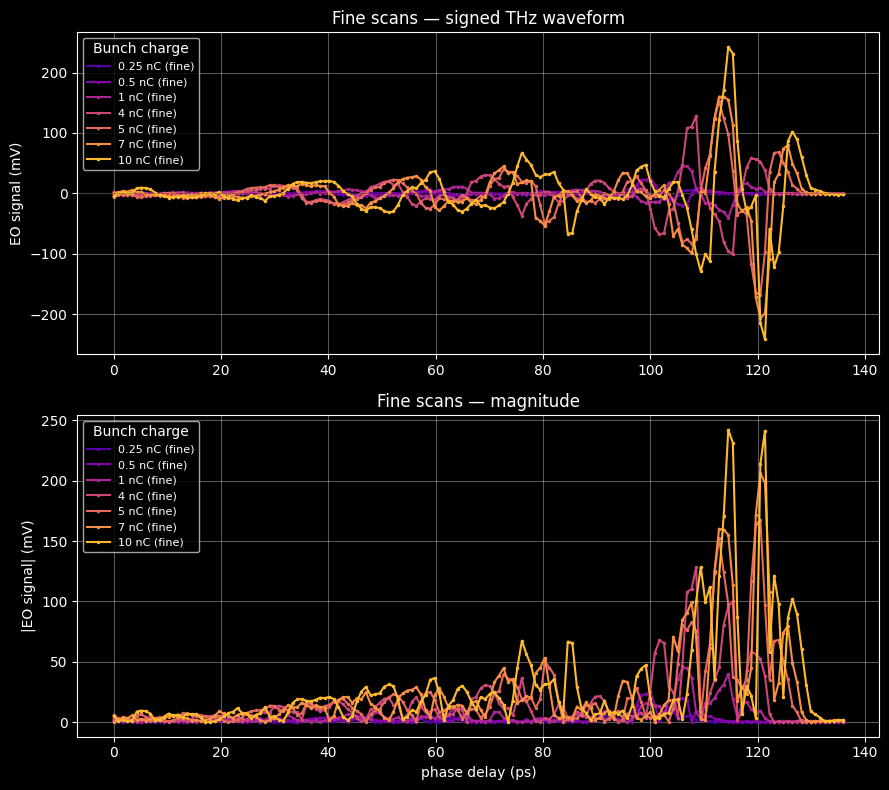

In [4]:
# ── Figure 1: EO waveform (signed) and magnitude — coarse and fine ────────────
# Top panel: signed amplitude vs delay — this IS the THz waveform E(t).
#   Positive = E_THz pushes BPD up; negative = pushes it down.
#   Sign changes are real: they reflect the bipolar THz electric field.
# Bottom panel: |signed| = magnitude, consistent with heatmap colour scale.

n_rows = sum([show_coarse, show_fine])
fig, axes = plt.subplots(n_rows * 2, 1, figsize=(9, 4 * n_rows * 2), squeeze=False)
ax_idx = 0

def plot_group_signed(ax_signed, ax_mag, results, title):
    colors = cm.plasma(np.linspace(0.15, 0.85, len(results)))
    for r, col in zip(results, colors):
        dp  = r['delay_ps']
        sig = mV * r['signed_amplitude']
        ax_signed.plot(dp, sig, color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
        ax_mag.plot(dp, np.abs(sig), color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
    ax_signed.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
    ax_signed.set_ylabel('EO signal (mV)')
    ax_signed.set_title(f'{title} — signed THz waveform')
    ax_signed.legend(title='Bunch charge', fontsize=8)
    ax_signed.grid(True, alpha=0.35)
    ax_mag.set_xlabel('phase delay (ps)')
    ax_mag.set_ylabel('|EO signal| (mV)')
    ax_mag.set_title(f'{title} — magnitude')
    ax_mag.legend(title='Bunch charge', fontsize=8)
    ax_mag.grid(True, alpha=0.35)

if show_coarse:
    plot_group_signed(axes[ax_idx, 0], axes[ax_idx + 1, 0],
                      results_coarse, 'Coarse scans')
    ax_idx += 2
if show_fine:
    plot_group_signed(axes[ax_idx, 0], axes[ax_idx + 1, 0],
                      results_fine, 'Fine scans')

plt.tight_layout()
plt.savefig('charge_comparison_amplitude.png', dpi=200)
plt.show()

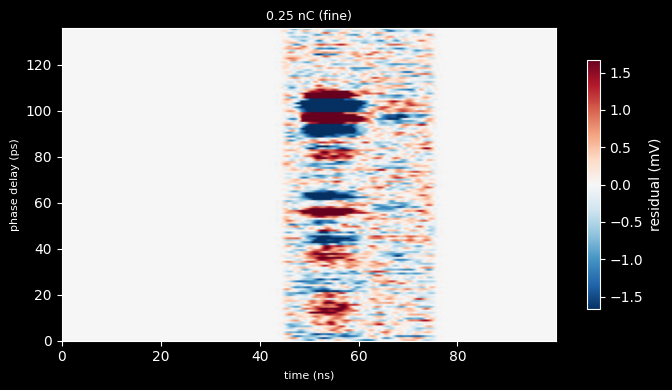

Saved Results/heatmaps/fine_0p25nC_heatmap.png


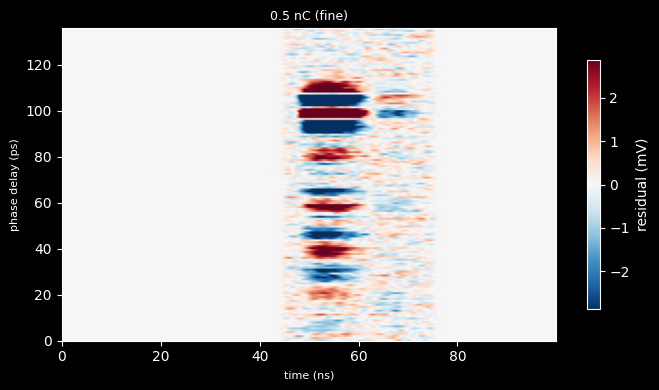

Saved Results/heatmaps/fine_0p5nC_heatmap.png


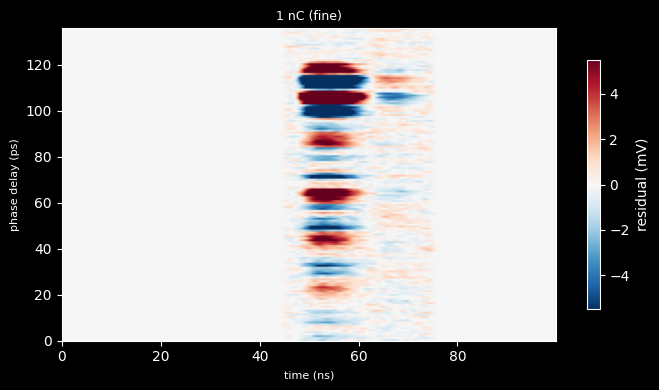

Saved Results/heatmaps/fine_1nC_heatmap.png


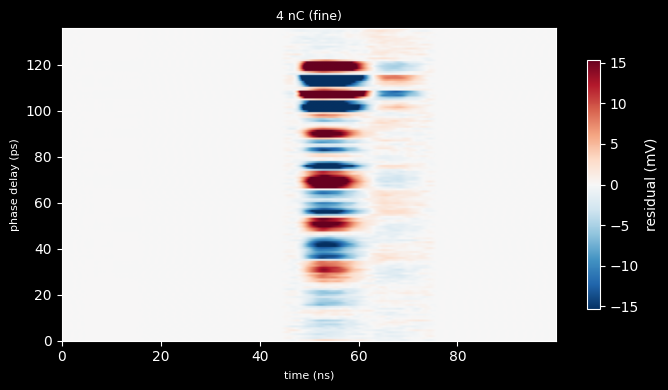

Saved Results/heatmaps/fine_4nC_heatmap.png


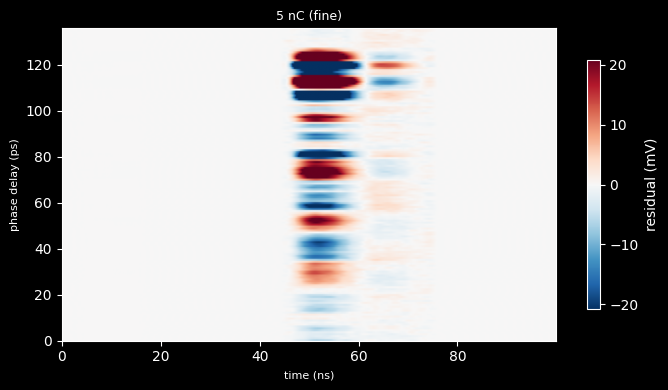

Saved Results/heatmaps/fine_5nC_heatmap.png


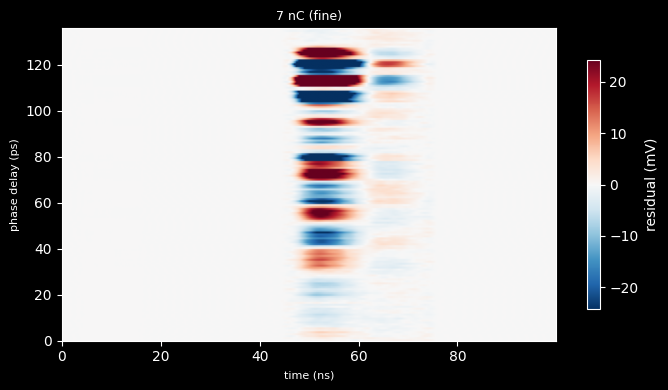

Saved Results/heatmaps/fine_7nC_heatmap.png


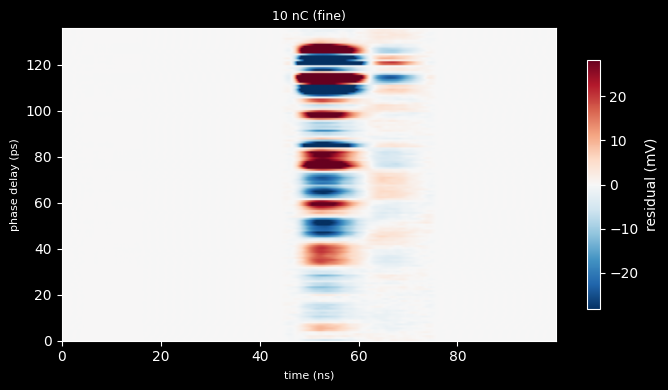

Saved Results/heatmaps/fine_10nC_heatmap.png


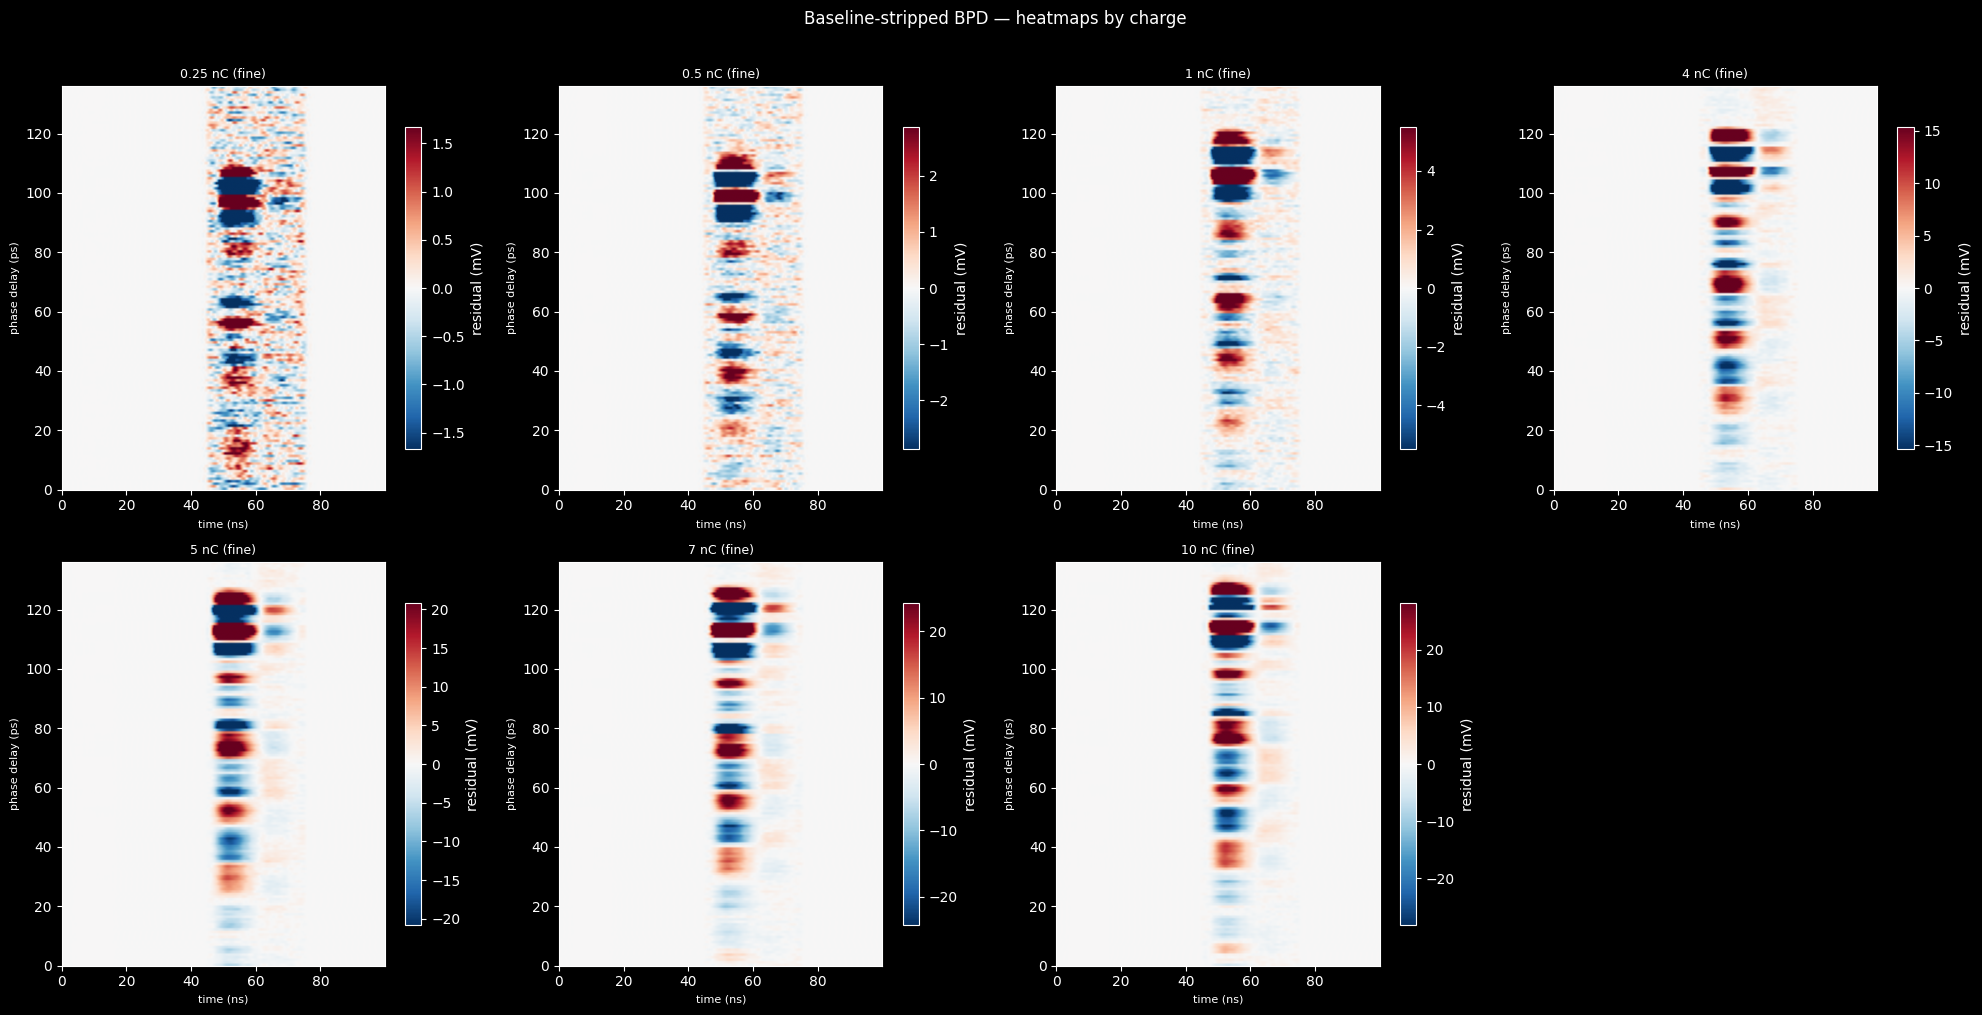

In [5]:
# ── Figure 2: Heatmaps — combined and individual per scan ─────────────────────

HEATMAP_COLS = 4   # panels per row in the combined figure

def label_to_filename(label):
    """'0.25 nC (fine)' → 'fine_0p25nC'"""
    charge = label.split()[0].replace('.', 'p')
    kind   = 'fine' if 'fine' in label else 'coarse'
    return f'{kind}_{charge}nC'

def draw_heatmap(ax, r, title=None):
    extent = [r['t_ns'][0], r['t_ns'][-1],
              r['delay_ps'][0], r['delay_ps'][-1]]
    vmax = np.percentile(np.abs(mV * r['residual']), 98)
    im = ax.imshow(mV * r['residual'], aspect='auto', extent=extent,
                   origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title or r['label'], fontsize=9)
    ax.set_xlabel('time (ns)', fontsize=8)
    ax.set_ylabel('phase delay (ps)', fontsize=8)
    plt.colorbar(im, ax=ax, label='residual (mV)', shrink=0.8)

# ── Individual file per fine scan ─────────────────────────────────────────────
if show_fine:
    for r in results_fine:
        fig, ax = plt.subplots(figsize=(7, 4))
        draw_heatmap(ax, r)
        plt.tight_layout()
        fname = f'{HEATMAP_DIR}/{label_to_filename(r["label"])}_heatmap.png'
        plt.savefig(fname, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'Saved {fname}')

# ── Combined overview: wrap into rows of HEATMAP_COLS ─────────────────────────
all_scans = []
if show_coarse: all_scans += results_coarse
if show_fine:   all_scans += results_fine

n_total = len(all_scans)
n_cols  = HEATMAP_COLS
n_rows  = int(np.ceil(n_total / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 5 * n_rows),
                         squeeze=False)

for idx, r in enumerate(all_scans):
    ax = axes[idx // n_cols, idx % n_cols]
    draw_heatmap(ax, r)

# Hide any unused panels in the last row
for idx in range(n_total, n_rows * n_cols):
    axes[idx // n_cols, idx % n_cols].set_visible(False)

plt.suptitle('Baseline-stripped BPD — heatmaps by charge', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/charge_comparison_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

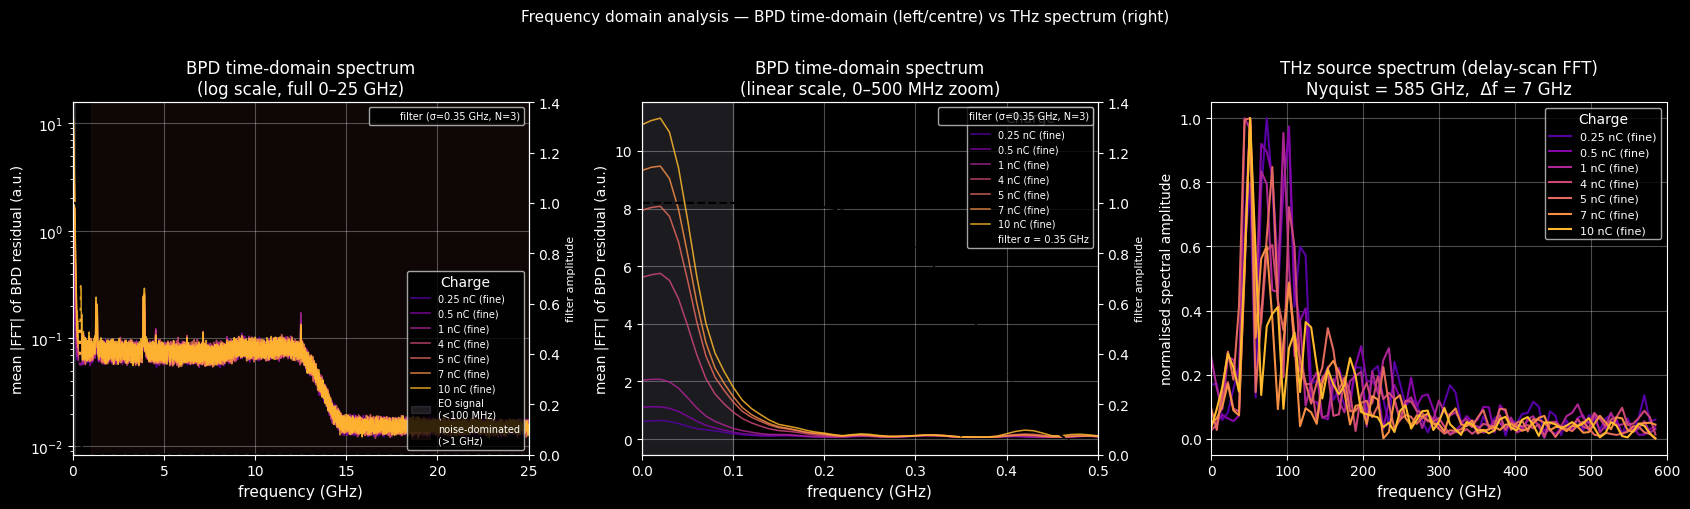

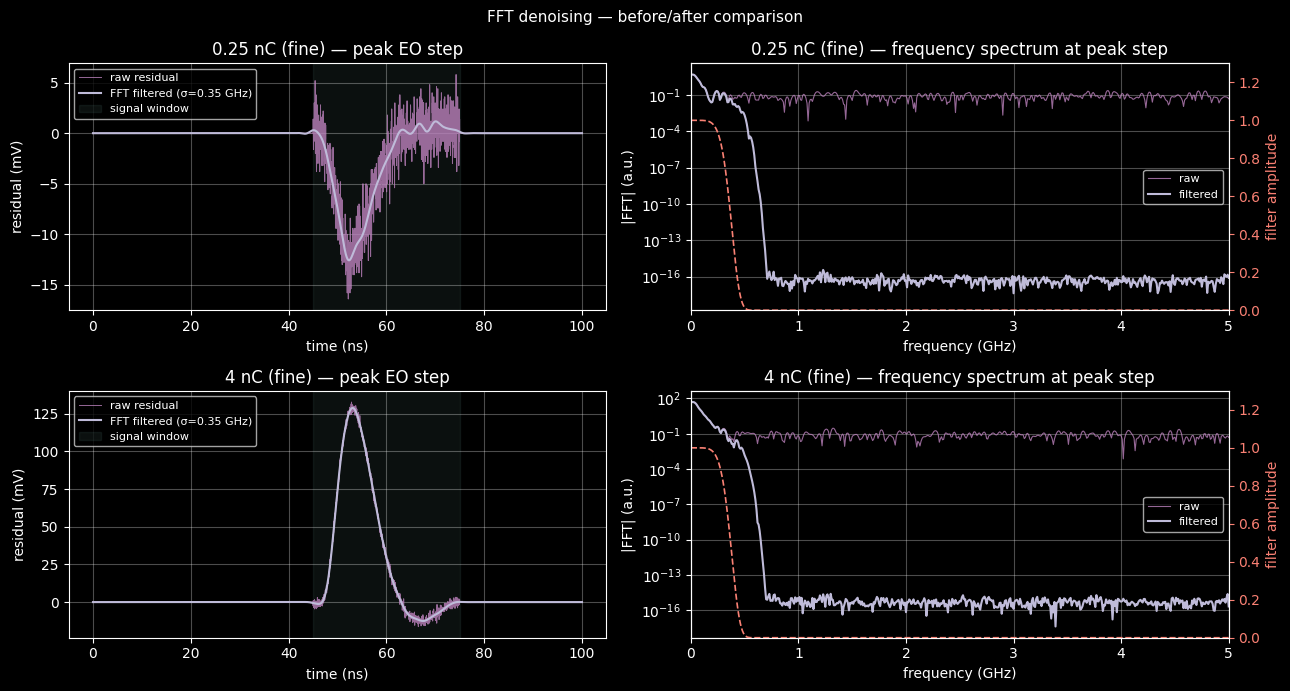

In [6]:

# ── Spectral analysis: time-domain BPD + THz delay scan ──────────────────────

def thz_spectrum(signed_amplitude, delay_ps):
    """FFT of EO waveform vs delay → THz frequency spectrum (0–585 GHz)."""
    n     = len(signed_amplitude)
    dt_ps = (delay_ps[-1] - delay_ps[0]) / (n - 1)
    win   = np.hanning(n)
    F     = np.fft.rfft(signed_amplitude * win)
    freqs = np.fft.rfftfreq(n, d=dt_ps * 1e-12) / 1e12   # THz
    return freqs, np.abs(F)


colors = cm.plasma(np.linspace(0.15, 0.85, len(results_fine)))

# ── Figure: three-panel spectral overview ─────────────────────────────────────
# Left:   FFT of the BPD residual in the 0–25 GHz time-domain space.
#         Shows where the EO probe signal lives vs noise and the filter cut-off.
# Middle: same, zoomed to 0–0.5 GHz to show the EO signal peak and filter.
# Right:  FFT of signed_amplitude vs delay — the THz source spectrum (0–600 GHz).

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for r, exp, col in zip(results_fine, fine_scans, colors):
    # ── BPD time-domain spectrum ──────────────────────────────────────────────
    d        = np.load(exp['path'])
    t_ns_ax  = 1e9 * d['x'][0, :]
    dt_ns    = (t_ns_ax[-1] - t_ns_ax[0]) / (len(t_ns_ax) - 1)
    r_raw    = load_and_strip(exp['path'], fft_sigma=0)    # unfiltered
    freqs_GHz = np.fft.rfftfreq(r_raw['residual'].shape[1], d=dt_ns)  # GHz

    # Mean amplitude spectrum across all phase steps
    mean_spec = np.abs(np.fft.rfft(r_raw['residual'], axis=1)).mean(axis=0)

    axes[0].semilogy(freqs_GHz, mean_spec, color=col, lw=1.1, alpha=0.85,
                     label=r['label'])
    axes[1].plot(freqs_GHz, mean_spec, color=col, lw=1.1, alpha=0.85,
                 label=r['label'])

    # ── THz delay-scan spectrum ───────────────────────────────────────────────
    freqs_thz, spec = thz_spectrum(r['signed_amplitude'], r['delay_ps'])
    axes[2].plot(freqs_thz * 1e3, spec / spec.max(), color=col, lw=1.5,
                 label=r['label'])

# ── Gaussian filter overlay on both BPD panels ────────────────────────────────
filt = np.exp(-0.5 * (freqs_GHz / FFT_SIGMA_GHZ) ** (2 * FFT_ORDER))
for ax_idx in [0, 1]:
    ax_twin = axes[ax_idx].twinx()
    ax_twin.plot(freqs_GHz, filt, 'k--', lw=1.5,
                 label=f'filter (σ={FFT_SIGMA_GHZ} GHz, N={FFT_ORDER})')
    ax_twin.set_ylabel('filter amplitude', fontsize=8)
    ax_twin.set_ylim(0, 1.4)
    ax_twin.legend(loc='upper right', fontsize=7)

# ── Panel 0: full BPD spectrum (log, 0–25 GHz) ────────────────────────────────
axes[0].axvspan(0, 0.1,  color='C2', alpha=0.15, label='EO signal\n(<100 MHz)')
axes[0].axvspan(1, 25,   color='C3', alpha=0.06, label='noise-dominated\n(>1 GHz)')
axes[0].set_xlim(0, 25)
axes[0].set_xlabel('frequency (GHz)', fontsize=11)
axes[0].set_ylabel('mean |FFT| of BPD residual (a.u.)', fontsize=10)
axes[0].set_title('BPD time-domain spectrum\n(log scale, full 0–25 GHz)')
axes[0].legend(title='Charge', fontsize=7, loc='lower right')
axes[0].grid(True, alpha=0.3)

# ── Panel 1: zoomed BPD spectrum (linear, 0–0.5 GHz) ─────────────────────────
axes[1].axvspan(0, 0.1,  color='C2', alpha=0.15)
axes[1].axvline(FFT_SIGMA_GHZ, color='k', ls=':', lw=1.2, alpha=0.6,
                label=f'filter σ = {FFT_SIGMA_GHZ} GHz')
axes[1].set_xlim(0, 0.5)
axes[1].set_xlabel('frequency (GHz)', fontsize=11)
axes[1].set_ylabel('mean |FFT| of BPD residual (a.u.)', fontsize=10)
axes[1].set_title('BPD time-domain spectrum\n(linear scale, 0–500 MHz zoom)')
axes[1].legend(title='Charge', fontsize=7, loc='upper right')
axes[1].grid(True, alpha=0.3)

# ── Panel 2: THz spectrum (0–600 GHz) ─────────────────────────────────────────
axes[2].set_xlabel('frequency (GHz)', fontsize=11)
axes[2].set_ylabel('normalised spectral amplitude', fontsize=10)
dp = results_fine[0]['delay_ps']
axes[2].set_title(f'THz source spectrum (delay-scan FFT)\n'
                  f'Nyquist = {0.5/(dp[1]-dp[0])*1e3:.0f} GHz,  '
                  f'Δf = {1e3/(len(dp)*(dp[1]-dp[0])):.0f} GHz')
axes[2].set_xlim(0, 600)
axes[2].legend(title='Charge', fontsize=8)
axes[2].grid(True, alpha=0.3)

plt.suptitle('Frequency domain analysis — BPD time-domain (left/centre) vs THz spectrum (right)',
             fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/frequency_analysis.png', dpi=200, bbox_inches='tight')
plt.show()


# ── Figure: denoising before/after comparison ─────────────────────────────────
_probe_cases = [
    ('0.25 nC (fine)', 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'),
    ('4 nC (fine)',    'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for row, (label, path) in enumerate(_probe_cases):
    r_raw  = load_and_strip(path, fft_sigma=0)
    r_filt = load_and_strip(path, fft_sigma=FFT_SIGMA_GHZ)
    peak_step = np.argmax(np.abs(r_filt['signed_amplitude']))
    t_ns_ax   = r_raw['t_ns']
    dt_ns_val = (t_ns_ax[-1] - t_ns_ax[0]) / (len(t_ns_ax) - 1)

    ax = axes[row, 0]
    ax.plot(t_ns_ax, mV * r_raw['residual'][peak_step],
            'C7', lw=0.7, alpha=0.8, label='raw residual')
    ax.plot(t_ns_ax, mV * r_filt['residual'][peak_step],
            'C2', lw=1.5, label=f'FFT filtered (σ={FFT_SIGMA_GHZ} GHz)')
    ax.axvspan(SIGNAL_START_NS, SIGNAL_END_NS, color='C0', alpha=0.08,
               label='signal window')
    ax.set_xlabel('time (ns)'); ax.set_ylabel('residual (mV)')
    ax.set_title(f'{label} — peak EO step')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    ax = axes[row, 1]
    freqs_GHz = np.fft.rfftfreq(len(t_ns_ax), d=dt_ns_val)
    ax.semilogy(freqs_GHz, np.abs(np.fft.rfft(r_raw['residual'][peak_step])),
                'C7', lw=0.8, alpha=0.8, label='raw')
    ax.semilogy(freqs_GHz, np.abs(np.fft.rfft(r_filt['residual'][peak_step])),
                'C2', lw=1.5, label='filtered')
    ax2 = ax.twinx()
    ax2.plot(freqs_GHz, np.exp(-0.5*(freqs_GHz/FFT_SIGMA_GHZ)**(2*FFT_ORDER)),
             'C3--', lw=1.2, label='Gaussian filter')
    ax2.set_ylabel('filter amplitude', color='C3')
    ax2.tick_params(axis='y', colors='C3'); ax2.set_ylim(0, 1.3)
    ax.set_xlim(0, 5); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('|FFT| (a.u.)')
    ax.set_title(f'{label} — frequency spectrum at peak step')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('FFT denoising — before/after comparison', fontsize=11)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/fft_denoising.png', dpi=200, bbox_inches='tight')
plt.show()


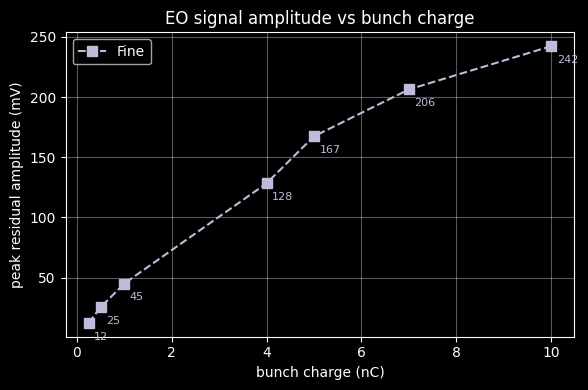

In [7]:
# ── Figure 3: Peak amplitude vs bunch charge ───────────────────────────────────

def extract_charge(label):
    """Parse numeric charge (nC) from label strings like '4 nC (fine)'."""
    return float(label.split()[0])

fig, ax = plt.subplots(figsize=(6, 4))

if show_coarse:
    qc = [extract_charge(r['label']) for r in results_coarse]
    pc = [mV * r['amplitude'].max() for r in results_coarse]
    ax.plot(qc, pc, 'C0o-', lw=1.5, markersize=7, label='Coarse')
    for q, p in zip(qc, pc):
        ax.annotate(f'{p:.0f}', xy=(q, p), xytext=(4, 4),
                    textcoords='offset points', fontsize=8, color='C0')

if show_fine:
    qf = [extract_charge(r['label']) for r in results_fine]
    pf = [mV * r['amplitude'].max() for r in results_fine]
    ax.plot(qf, pf, 'C2s--', lw=1.5, markersize=7, label='Fine')
    for q, p in zip(qf, pf):
        ax.annotate(f'{p:.0f}', xy=(q, p), xytext=(4, -12),
                    textcoords='offset points', fontsize=8, color='C2')

ax.set_xlabel('bunch charge (nC)')
ax.set_ylabel('peak residual amplitude (mV)')
ax.set_title('EO signal amplitude vs bunch charge')
ax.legend()
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('charge_comparison_scaling.png', dpi=200)
plt.show()

In [8]:

# ── Charge measurement from ICT + error bar computation ───────────────────────
# The ictwf array stores the Integrating Current Transformer waveform for each
# phase step.  It gives the actual per-shot bunch charge, independent of ND
# filter settings.  We use it to:
#   1. Calibrate the x-axis: ICT peak → actual charge in nC
#   2. Compute horizontal error bars: shot-to-shot RMS charge within each scan
#   3. Compute vertical error bars: EO signal noise floor at non-THz delay steps

from scipy import stats as sp_stats

# ICT waveform structure: (steps, channels, 2502 samples)
# Baseline quiet regions: samples 0-800 and 1300-2502 (pulse peaks ~sample 935)
ICT_BL_PRE  = slice(None, 800)
ICT_BL_POST = slice(1300, None)

def ict_per_step(path):
    """
    Returns per-step baseline-corrected ICT peak amplitude (positive, in V).
    Averages across all ICT channels (all measure the same charge).
    """
    d   = np.load(path)
    ict = d['ictwf']                                           # (steps, ch, 2502)
    bl  = np.concatenate([ict[:, :, ICT_BL_PRE],
                          ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)  # (steps, ch)
    peak = ict.min(axis=2) - bl                               # (steps, ch), negative
    return -peak.mean(axis=1)                                  # (steps,), positive V


def eo_noise_floor(signed_amplitude, delay_ps, signal_frac=0.3):
    """
    Estimate EO amplitude noise floor from the delay steps farthest from
    the THz peak (the outer `signal_frac` fraction of the delay range).
    Returns the RMS of those quiet steps.
    """
    n    = len(delay_ps)
    n_edge = max(1, int(n * signal_frac / 2))
    quiet  = np.concatenate([signed_amplitude[:n_edge], signed_amplitude[-n_edge:]])
    return np.std(quiet)


# ── Fit ICT calibration across fine scans ─────────────────────────────────────
# Q_nC = k * ICT_V + b  (linear fit through all fine scans)
_ict_means, _Q_noms = [], []
for exp in fine_scans:
    mu = ict_per_step(exp['path']).mean()
    _ict_means.append(mu)
    _Q_noms.append(float(exp['label'].split()[0]))

_ict_means = np.array(_ict_means)
_Q_noms    = np.array(_Q_noms)
_fit       = sp_stats.linregress(_ict_means, _Q_noms)
ICT_K      = _fit.slope      # nC / V
ICT_B      = _fit.intercept  # nC
print(f'ICT calibration:  Q = {ICT_K:.2f} × ICT_V + {ICT_B:.3f} nC   R²={_fit.rvalue**2:.4f}')
print()

# ── Collect (charge, EO amplitude) with errors for each group ─────────────────
def build_errorbars(results, scans, ict_k=ICT_K, ict_b=ICT_B):
    """
    For each scan compute:
      Q_mean  — mean calibrated charge [nC]
      Q_err   — RMS charge uncertainty (horizontal error bar) [nC]
      S_peak  — peak |EO amplitude| [mV]
      S_err   — EO noise floor (vertical error bar) [mV]
    """
    Qs, Q_errs, Ss, S_errs = [], [], [], []
    for r, exp in zip(results, scans):
        per_step  = ict_per_step(exp['path'])
        Q_mean    = ict_k * per_step.mean() + ict_b
        Q_err     = ict_k * per_step.std()
        S_peak    = mV * r['amplitude'].max()
        S_err     = mV * eo_noise_floor(r['signed_amplitude'], r['delay_ps'])
        Qs.append(Q_mean);  Q_errs.append(Q_err)
        Ss.append(S_peak);  S_errs.append(S_err)
    return np.array(Qs), np.array(Q_errs), np.array(Ss), np.array(S_errs)


fits = {}

if show_coarse and results_coarse:
    Qc, Qce, Sc, Sce = build_errorbars(results_coarse, coarse_scans)
    fits['Coarse'] = {'Q': Qc, 'Q_err': Qce, 'S': Sc, 'S_err': Sce}

if show_fine and results_fine:
    Qf, Qfe, Sf, Sfe = build_errorbars(results_fine, fine_scans)
    fits['Fine'] = {'Q': Qf, 'Q_err': Qfe, 'S': Sf, 'S_err': Sfe}


# ── Linear regression (origin-forced) ─────────────────────────────────────────
def origin_fit(Q, S):
    slope   = (Q * S).sum() / (Q * Q).sum()
    resid   = S - slope * Q
    stderr  = np.sqrt((resid**2).sum() / ((len(Q) - 1) * (Q**2).sum()))
    r2      = 1 - (resid**2).sum() / ((S - S.mean())**2).sum()
    return slope, stderr, r2


print(f"{'Group':<10}  {'Sensitivity':>18}  {'Q range (nC)':>16}  R²")
print('-' * 60)
for name, f in fits.items():
    slope, se, r2 = origin_fit(f['Q'], f['S'])
    print(f"{name:<10}  {slope:.2f} ± {se:.2f} mV/nC          "
          f"{f['Q'].min():.2f} – {f['Q'].max():.2f}          {r2:.4f}")
    print(f"          (Q_err: {f['Q_err'].min():.2f}–{f['Q_err'].max():.2f} nC  "
          f"S_err: {f['S_err'].min():.1f}–{f['S_err'].max():.1f} mV)")
    print()


ICT calibration:  Q = 21.62 × ICT_V + -0.253 nC   R²=0.9929

Group              Sensitivity      Q range (nC)  R²
------------------------------------------------------------
Fine        27.70 ± 1.42 mV/nC          0.11 – 9.79          0.9546
          (Q_err: 0.01–0.36 nC  S_err: 0.7–59.5 mV)



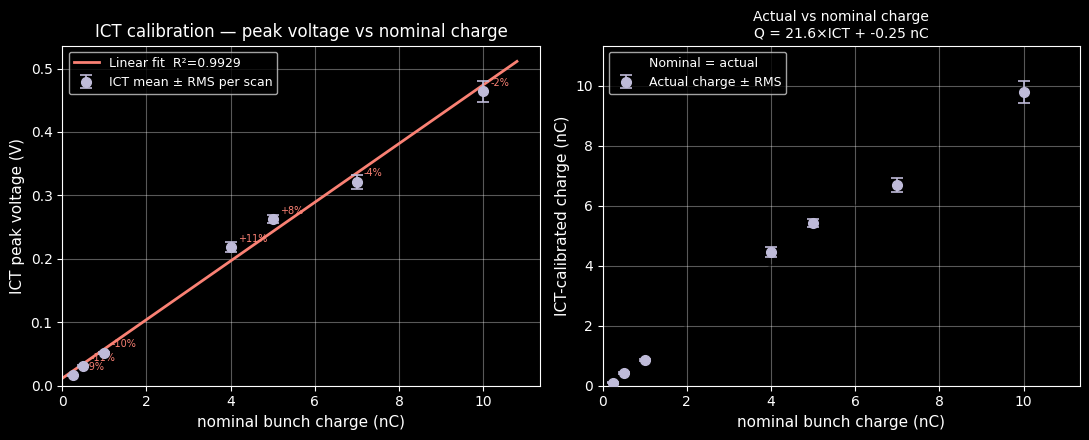

In [9]:

# ── Figure: ICT calibration fit ───────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# ── Left: ICT mean peak vs nominal charge ─────────────────────────────────────
ax = axes[0]
ict_means_plot = np.array(_ict_means)
ict_stds_plot  = np.array([ict_per_step(e['path']).std() for e in fine_scans])

ax.errorbar(_Q_noms, ict_means_plot, yerr=ict_stds_plot,
            fmt='C2o', capsize=4, capthick=1.2, elinewidth=1.2,
            markersize=7, zorder=5, label='ICT mean ± RMS per scan')

# Fit line: ICT_V = (Q_nom - B) / K
Q_fit = np.linspace(0, _Q_noms.max() * 1.08, 300)
ict_fit = (Q_fit - ICT_B) / ICT_K
ax.plot(Q_fit, ict_fit, 'C3-', lw=2,
        label=f'Linear fit  R²={_fit.rvalue**2:.4f}')

ax.set_xlabel('nominal bunch charge (nC)', fontsize=11)
ax.set_ylabel('ICT peak voltage (V)', fontsize=11)
ax.set_title('ICT calibration — peak voltage vs nominal charge')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.35)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

# Annotate each point with residual from fit
for Q, ict, label in zip(_Q_noms, ict_means_plot, [e['label'] for e in fine_scans]):
    ict_pred = (Q - ICT_B) / ICT_K
    residual_pct = 100 * (ict - ict_pred) / ict_pred
    ax.annotate(f'{residual_pct:+.0f}%', xy=(Q, ict),
                xytext=(5, 4), textcoords='offset points', fontsize=7, color='C3')

# ── Right: calibrated actual charge vs nominal charge ─────────────────────────
ax = axes[1]
Q_actual = ICT_K * ict_means_plot + ICT_B
Q_err    = ICT_K * ict_stds_plot

ax.errorbar(_Q_noms, Q_actual, yerr=Q_err,
            fmt='C2o', capsize=4, capthick=1.2, elinewidth=1.2,
            markersize=7, zorder=5, label='Actual charge ± RMS')

# 1:1 reference line
q_range = np.array([0, _Q_noms.max() * 1.08])
ax.plot(q_range, q_range, 'k--', lw=1.2, alpha=0.5, label='Nominal = actual')

ax.set_xlabel('nominal bunch charge (nC)', fontsize=11)
ax.set_ylabel('ICT-calibrated charge (nC)', fontsize=11)
ax.set_title(f'Actual vs nominal charge\n'
             f'Q = {ICT_K:.1f}×ICT + {ICT_B:.2f} nC', fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.35)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/ict_calibration.png', dpi=200)
plt.show()


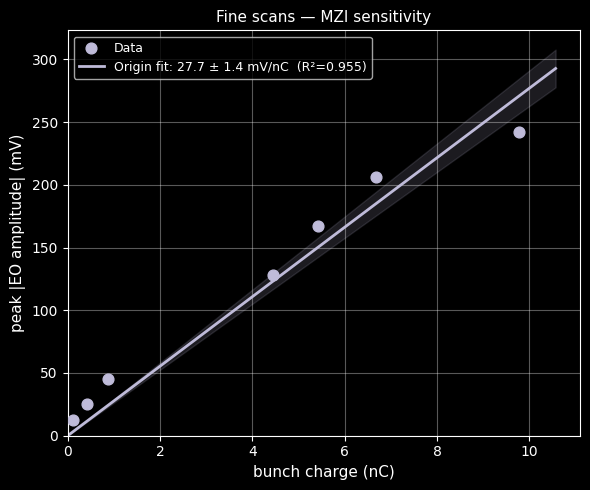

In [10]:

# ── Figure 4: Sensitivity fit ─────────────────────────────────────────────────

n_panels = len(fits)
fig, axes = plt.subplots(1, n_panels, figsize=(6 * n_panels, 5), squeeze=False)
palette = {'Coarse': 'C0', 'Fine': 'C2'}

for ax, (name, f) in zip(axes[0], fits.items()):
    col   = palette.get(name, 'C0')
    Q     = f['Q']
    S     = f['S']
    Q_fit = np.linspace(0, Q.max() * 1.08, 300)

    # Data points
    ax.scatter(Q, S, color=col, zorder=5, s=60, label='Data')

    # Origin-forced fit + 1σ band
    slope, se, r2 = origin_fit(Q, S)
    ax.plot(Q_fit, slope * Q_fit, color=col, lw=2,
            label=f'Origin fit: {slope:.1f} ± {se:.1f} mV/nC  (R²={r2:.3f})')
    ax.fill_between(Q_fit,
                    (slope - se) * Q_fit, (slope + se) * Q_fit,
                    color=col, alpha=0.15)

    ax.set_xlabel('bunch charge (nC)', fontsize=11)
    ax.set_ylabel('peak |EO amplitude| (mV)', fontsize=11)
    ax.set_title(f'{name} scans — MZI sensitivity', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.35)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('sensitivity_fit.png', dpi=200)
plt.show()
